In [1]:
# -*-coding:utf-8-*-
# Project: CH02
# Filename: perceptron
# Author: 😏 <smirk dot cao at gmail dot com>
import numpy as np
import random
import argparse
import logging

In [144]:
w_real,b_real = np.array([3,2]),1
def gen_data(size=100, dim=2):
    """生成线性可分的数据"""
    X = np.random.randn(size, dim)
    y = ((X @ w_real + b_real)+np.random.randn()*0.1 > 0.5).astype(int)
    y[y==0] = -1
    return X, y

x_train, y_train = gen_data()
print("w_real:",w_real,"b_real:",b_real)
print(x_train,y_train)


w_real: [3 2] b_real: 1
[[-0.41374951  0.36428802]
 [ 1.084841   -1.38946416]
 [-1.0321793  -0.95123201]
 [-0.67484955 -0.73252   ]
 [ 0.03873041  1.75160265]
 [ 0.62083589 -0.72535279]
 [-1.18880139 -2.09402622]
 [ 0.75941273  0.26486181]
 [ 0.79343184  1.74951295]
 [-0.17918994  0.1479282 ]
 [ 0.29759542  0.9189879 ]
 [-0.02826154 -0.43937685]
 [ 0.36029552 -0.93959924]
 [-0.12704158  1.42614551]
 [-1.25923738  2.22145655]
 [-0.85930139 -0.60995645]
 [-0.23496149  0.96724265]
 [ 0.46900497 -1.29255692]
 [-0.94525136  0.17605617]
 [ 2.01111538 -0.61077769]
 [-0.28026748  0.59911791]
 [-1.3463862   1.12050344]
 [ 0.06061105 -0.69826664]
 [-1.47819903  1.27006777]
 [ 1.31610808  0.53732898]
 [-1.00010428  0.05859712]
 [-0.19570093  0.78614643]
 [-0.29421052  0.23681247]
 [ 0.45972206  0.77774105]
 [ 0.58341911 -1.15761768]
 [ 0.19497305 -0.31432299]
 [ 1.27171868 -1.09688006]
 [ 0.01742926 -0.72818818]
 [-1.01897028  0.79476194]
 [ 2.06798077  0.40001379]
 [ 0.27320162  0.76617465]
 [ 2

In [145]:
class GanZhiJi(object):
    def __init__(self,dim=2):
        super(GanZhiJi,self).__init__()
        self.w = np.zeros(dim)
        self.b = 0.0

    def sign(self,x):
        return 1 if x > 0 else -1

    def forward(self,input):
        return self.sign(np.dot(self.w,input) + self.b)
    
    def fit(self,epochs,input, label):
        for epoch in range(epochs):
            for x,y in zip(input,label):
                y_hat = self.forward(x)
                if y_hat != y:
                    self.w += np.dot(y,x)*0.1
                    self.b += y
    
gan = GanZhiJi(dim=2)
gan.fit(epochs=100,input=x_train, label=y_train)

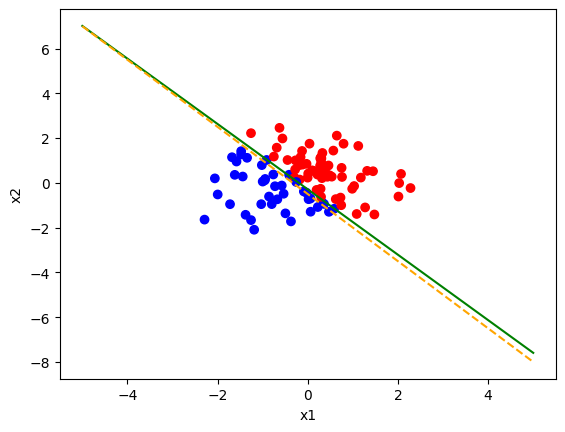

In [146]:
%matplotlib inline

import matplotlib.pyplot as plt
x = np.linspace(-5, 5, 100)
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, cmap='bwr', label='Data Points')
plt.plot(x, (-gan.w[0]*x-gan.b)/gan.w[1], label='Decision Boundary', color='green')
plt.plot(x, (-w_real[0]*x-b_real)/w_real[1], label='Real Boundary', color='orange', linestyle='--')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

In [ ]:
class Perceptron(object):
    def __init__(self,
                 max_iter=5000,
                 eta=0.00001,
                 verbose=True):
        self.eta_ = eta
        self.max_iter_ = max_iter
        self.w = 0
        self.verbose = verbose

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1] + 1)
        # correct_count = 0
        n_iter_ = 0

        while n_iter_ < self.max_iter_:
            index = random.randint(0, y.shape[0] - 1)
            xx_ = np.hstack([X[index], 1])
            # for $y \in \Y=\{0, 1\}$ case
            yy_ = 2 * y[index] - 1
            # logger.info(xx_)
            # logger.info(yy_)
            wx = np.dot(self.w, xx_)

            # if wx * yy_ > 0:
            #     correct_count += 1
            #     if correct_count > self.max_iter_:
            #         logger.info(correct_count)
            #         break
            #     continue
            #
            # self.w += self.eta_ * yy_ * xx_
            # n_iter_ += 1
            # if self.verbose:
            #     print(n_iter_)
            # 上面这部分换个表达方式，希望更好理解
            if wx * yy_ <= 0:
                self.w += self.eta_ * yy_ * xx_
            n_iter_ += 1
            if self.verbose:
                logger.info(n_iter_)

    def predict(self, X):
        # for b
        X = np.hstack([X, np.ones(X.shape[0]).reshape((-1, 1))])
        # activation function for perceptron: sign
        rst = np.array([1 if rst else -1 for rst in np.dot(X, self.w) > 0])
        # np.sign(0) == 0
        # rst = np.sign(np.dot(X, self.w))
        return rst


if __name__ == '__main__':
    logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(name)s - %(levelname)s - %(message)s')
    logger = logging.getLogger(__name__)

    ap = argparse.ArgumentParser()
    ap.add_argument("-p", "--path", required=False, help="path to input data file")
    args = vars(ap.parse_args())
else:
    logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(name)s - %(levelname)s - %(message)s')
    logger = logging.getLogger(__name__)